In [1]:
! pip install kaggle

In [2]:
!pip install --upgrade kaggle

  Attempting uninstall: kaggle
    Found existing installation: kaggle 2.0.2
    Uninstalling kaggle-2.0.2:
      Successfully uninstalled kaggle-2.0.2


# **IMPORTING THE DEPENDENCIES**

In [3]:
import numpy as np , pandas as pd
import json , os
from zipfile import ZipFile

In [5]:
kaggle_directory = json.load(open('kaggle.json'))

In [6]:
kaggle_directory.keys()

dict_keys(['username', 'key'])

In [7]:
os.environ['KAGGLE_USERNAME'] = kaggle_directory['username']
os.environ['KAGGLE_KEY'] = kaggle_directory['key']

In [8]:
!kaggle kernels pull semanto117119/sentiment-analysis-using-lstm -m

Source code and metadata downloaded to /content


In [9]:
!ls

kaggle.json	      sample_data
kernel-metadata.json  sentiment-analysis-using-lstm.ipynb


In [10]:
import json

with open('/content/kernel-metadata.json', 'r') as f:
    metadata = json.load(f)

print("Dataset sources:", metadata.get('dataset_sources'))

Dataset sources: ['lakshmi25npathi/imdb-dataset-of-50k-movie-reviews']


In [11]:
with ZipFile('sentiment-analysis-using-lstm.zip','r') as zip:
  zip.extractall()

FileNotFoundError: [Errno 2] No such file or directory: 'sentiment-analysis-using-lstm.zip'

In [12]:
# Download dataset from Kaggle
!kaggle datasets download -d lakshmi25npathi/imdb-dataset-of-50k-movie-reviews -p /content

# Extract the downloaded ZIP
!unzip -q /content/imdb-dataset-of-50k-movie-reviews.zip -d /content/imdb_dataset

# Check extracted files
!ls -lh /content/imdb_dataset

Dataset URL: https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews
License(s): other
100% 25.7M/25.7M [00:02<00:00, 11.5MB/s]

total 64M
-rw-r--r-- 1 root root 64M Oct 19  2019 'IMDB Dataset.csv'


In [13]:
df = pd.read_csv('/content/imdb_dataset/IMDB Dataset.csv')

df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [14]:
# Dataset dimensions
print("Shape:", df.shape)

# Column names and data types
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Count positive and negative reviews
print("\nSentiment Distribution:")
print(df['sentiment'].value_counts())

Shape: (50000, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB

Missing Values:
review       0
sentiment    0
dtype: int64

Duplicate Records: 418

Sentiment Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [15]:
# Remove duplicate records
df.drop_duplicates(inplace=True)

# Reset index after removing duplicates
df.reset_index(drop=True, inplace=True)

# Verify the changes
print("Updated shape:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Updated shape: (49582, 2)
Remaining duplicates: 0


In [16]:
# Convert categorical labels into numerical values
df['sentiment'] = df['sentiment'].map({
    'negative': 0,
    'positive': 1
})

# Check the conversion
print(df['sentiment'].value_counts())

# Display first 5 records
display(df.head())

sentiment
1    24884
0    24698
Name: count, dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,1
2,I thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",1


In [17]:
import re
import html

# Function to clean text
def clean_text(text):

    # Convert text into lowercase
    text = text.lower()

    # Decode HTML entities (&amp; -> &)
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\.\S+', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Apply cleaning to all reviews
df['review'] = df['review'].apply(clean_text)

# Display cleaned reviews
display(df.head())

,review,sentiment
0,one of the other reviewers has mentioned that ...,1
1,a wonderful little production. the filming tec...,1
2,i thought this was a wonderful way to spend ti...,1
3,basically there's a family where a little boy ...,0
4,"petter mattei's ""love in the time of money"" is...",1


In [18]:
print(df['review'].iloc[0])

one of the other reviewers has mentioned that after watching just 1 oz episode you'll be hooked. they are right, as this is exactly what happened with me.the first thing that struck me about oz was its brutality and unflinching scenes of violence, which set in right from the word go. trust me, this is not a show for the faint hearted or timid. this show pulls no punches with regards to drugs, sex or violence. its is hardcore, in the classic use of the word.it is called oz as that is the nickname given to the oswald maximum security state penitentary. it focuses mainly on emerald city, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. em city is home to many..aryans, muslims, gangstas, latinos, christians, italians, irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.i would say the main appeal of the show is due to the fact that it goes where other shows wou

In [25]:
# Input features: movie reviews
X = df['review'].values

# Target labels: sentiment (0 or 1)
y = df['sentiment'].values

In [24]:
X

,review
0,one of the other reviewers has mentioned that ...
1,a wonderful little production. the filming tec...
2,i thought this was a wonderful way to spend ti...
3,basically there's a family where a little boy ...
4,"petter mattei's ""love in the time of money"" is..."
...,...
49577,i thought this movie did a down right good job...
49578,"bad plot, bad dialogue, bad acting, idiotic di..."
49579,i am a catholic taught in parochial elementary...
49580,i'm going to have to disagree with the previou...


In [26]:
y

array([1, 1, 1, ..., 0, 0, 0])

In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check dataset sizes
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 39665
Testing samples: 9917


In [34]:
from tensorflow.keras.preprocessing.text import Tokenizer
# Set maximum vocabulary size
vocab_size = 10000

# Create tokenizer
tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

# Learn the vocabulary from training reviews only
tokenizer.fit_on_texts(X_train)

In [30]:
X_train_sequences = tokenizer.texts_to_sequences(X_train)
X_test_sequences = tokenizer.texts_to_sequences(X_test)

In [31]:
print("Original Review:")
print(X_train[0][:300])

print("\nNumerical Sequence:")
print(X_train_sequences[0][:30])

print("\nTotal unique words:", len(tokenizer.word_index))

Original Review:
i am one of jehovah's witnesses and i also work in an acute care medical facility. over the years i have seen people die from hemolytic reactions to blood transfusions, have attended numerous conferences on blood born pathogens, and have seen several patients become seriously ill from pathogens indu

Numerical Sequence:
[10, 238, 27, 5, 1, 5002, 3, 10, 81, 158, 8, 32, 1, 456, 2798, 8066, 121, 2, 151, 10, 25, 105, 83, 708, 35, 1, 3831, 6, 552, 1]

Total unique words: 113111


In [35]:
import numpy as np

# Calculate the length of every training review
review_lengths = [len(sequence) for sequence in X_train_sequences]

# Check different statistics
print("Shortest review:", np.min(review_lengths))
print("Longest review:", np.max(review_lengths))
print("Average length:", np.mean(review_lengths))

print("\nPercentile lengths:")
print("90th percentile:", np.percentile(review_lengths, 90))
print("95th percentile:", np.percentile(review_lengths, 95))
print("99th percentile:", np.percentile(review_lengths, 99))

Shortest review: 6
Longest review: 2466
Average length: 231.29834867011218

Percentile lengths:
90th percentile: 449.0
95th percentile: 588.0
99th percentile: 908.0


In [36]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

maxlen = 600

X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=maxlen,
    padding='post',
    truncating='post'
)

X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=maxlen,
    padding='post',
    truncating='post'
)

In [37]:
print("Training shape:", X_train_padded.shape)
print("Testing shape:", X_test_padded.shape)

print("\nExample padded sequence:")
print(X_train_padded[0])

Training shape: (39665, 600)
Testing shape: (9917, 600)

Example padded sequence:
[  10  238   27    5    1 5002    3   10   81  158    8   32    1  456
 2798 8066  121    2  151   10   25  105   83  708   35    1 3831    6
  552    1   25 6566 1926    1   20  552 1425    1    3   25  105  439
 5050  430  610 1760   35    1 8682   31    1  552   10   25   81  551
  439    1 5002  109  565   12   33   79  708   43   33 5898  552    3
  100 8498  151    8    2 1861   10   25  110  159  105    9  581 1213
    2  901    7    9   62    1    6 5898  552    1   38    7    2 1942
   30 1034    1   35    2  933   20   11 1770    2 1770   15    1 5002
    7    4 1540   27   22  206    1   35  552    7   21   32 5543 2591
 1398   22   15   11   16    3 3541  786   20    9    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0 

In [38]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dropout, Dense

model = Sequential([

    # Input layer
    Input(shape=(maxlen,)),

    # Embedding layer
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        mask_zero=True
    ),

    # LSTM layer
    LSTM(64),

    # Dropout layer
    Dropout(0.3),

    # Output layer
    Dense(1, activation='sigmoid')
])

In [39]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 600, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,329,473 (5.07 MB)

 Trainable params: 1,329,473 (5.07 MB)

 Non-trainable params: 0 (0.00 B)

In [40]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [41]:
from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss stops improving
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train_padded,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop]
)

Epoch 1/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 672s 597ms/step - accuracy: 0.8125 - loss: 0.4161 - val_accuracy: 0.8593 - val_loss: 0.3277
Epoch 2/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 636s 570ms/step - accuracy: 0.7332 - loss: 0.5369 - val_accuracy: 0.7192 - val_loss: 0.5552
Epoch 3/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 633s 566ms/step - accuracy: 0.7817 - loss: 0.4768 - val_accuracy: 0.8488 - val_loss: 0.3882


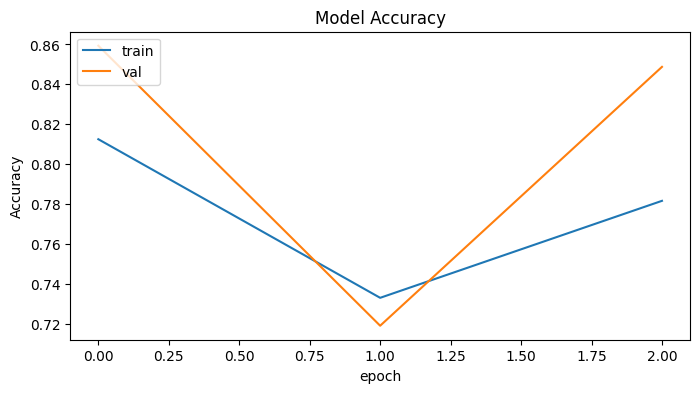

In [45]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('epoch')
plt.legend(['train','val'],loc='upper left')
plt.show()

In [46]:
test_loss, test_accuracy = model.evaluate(
    X_test_padded,
    y_test,
    batch_size=32
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

310/310 ━━━━━━━━━━━━━━━━━━━━ 37s 117ms/step - accuracy: 0.8658 - loss: 0.3183
Test Loss: 0.3183234632015228
Test Accuracy: 86.57860159873962 %


In [47]:
import numpy as np

# Predict probabilities
y_pred_prob = model.predict(
    X_test_padded,
    batch_size=32
)

# Convert probabilities into binary labels
y_pred = (y_pred_prob >= 0.5).astype(int).ravel()

print("Actual labels:", y_test[:10])
print("Predicted labels:", y_pred[:10])

310/310 ━━━━━━━━━━━━━━━━━━━━ 42s 134ms/step
Actual labels: [0 1 1 0 0 1 0 0 1 0]
Predicted labels: [0 1 1 0 0 1 1 0 1 0]


In [48]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print(cm)

[[4077  863]
 [ 468 4509]]


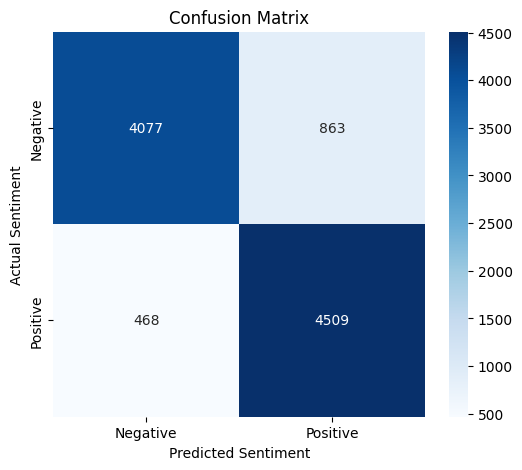

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.title('Confusion Matrix')

plt.show()

In [50]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Negative', 'Positive']
    )
)

              precision    recall  f1-score   support

    Negative       0.90      0.83      0.86      4940
    Positive       0.84      0.91      0.87      4977

    accuracy                           0.87      9917
   macro avg       0.87      0.87      0.87      9917
weighted avg       0.87      0.87      0.87      9917



In [51]:
def predict_sentiment(review):

    # Step 1: Clean the input review
    cleaned_review = clean_text(review)

    # Step 2: Convert text into numerical sequence
    sequence = tokenizer.texts_to_sequences([cleaned_review])

    # Step 3: Apply padding
    padded_sequence = pad_sequences(
        sequence,
        maxlen=maxlen,
        padding='post',
        truncating='post'
    )

    # Step 4: Predict probability
    probability = model.predict(padded_sequence, verbose=0)[0][0]

    # Step 5: Convert probability into sentiment
    if probability >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print("Positive probability:", round(float(probability), 4))

    return sentiment

In [54]:
review1 = "This movie was fucking Bad. I did not loved every moment of it."

review2 = "This was the worst movie I have ever watched. Completely boring."

predict_sentiment(review1)

print("--------------------------")

predict_sentiment(review2)

Review: This movie was fucking Bad. I did not loved every moment of it.
Predicted sentiment: Negative
Positive probability: 0.392
--------------------------
Review: This was the worst movie I have ever watched. Completely boring.
Predicted sentiment: Negative
Positive probability: 0.0192


'Negative'

In [56]:
import json

# Save the trained LSTM model
model.save("/content/sentiment_model.keras")

# Save the tokenizer as JSON
tokenizer_json = tokenizer.to_json()

with open("/content/tokenizer.json", "w") as file:
    file.write(tokenizer_json)

print("Model and tokenizer saved successfully!")

Model and tokenizer saved successfully!


In [57]:
!ls -lh /content/sentiment_model.keras /content/tokenizer.json

-rw-r--r-- 1 root root 16M Oct 31 08:50 /content/sentiment_model.keras
-rw-r--r-- 1 root root 11M Oct 31 08:50 /content/tokenizer.json
